# Analisis Percobaan Perbaikan Validasi SRL

Eksperimen ini mengevaluasi BiLSTM, IndoBERT, dan CRF dari artefak tersimpan, tanpa training baru. Hasil digunakan sebagai analisis percobaan dan keterbatasan generalisasi, bukan klaim bahwa perbaikan validasi menghilangkan overfitting.

IndoRoBERTa dan GPT dikeluarkan karena rangkaian training perbaikan belum lengkap; Komodo dikeluarkan karena bukti checkpoint dan protokol validation tetap belum memadai. Artefak sumber tetap disimpan untuk arsip.


## 1. Tujuan dan lingkungan eksperimen

Reproduksi dilakukan melalui implementasi mandiri karena source code paper tidak tersedia dalam bahan proyek.
Targetnya mengidentifikasi 15 label token SRL, termasuk FALSE-EVENT, lalu membandingkan hasil dengan paper.

PyTorch yang sudah terpasang digunakan untuk inferensi; model/tokenizer dimuat **lokal**, tanpa download otomatis.
Notebook memerlukan dataset dan artefak pada folder proyek. Output laporan baru berada di `outputs/unified/`.
File sumber asli berada di `archive/`; notebook Komodo Colab berada di `imports/komodo/`.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'unified_srl.py').is_file():
    raise RuntimeError('Buka root folder proyek sebagai working directory notebook.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
RUN_TRAINING = False
assert RUN_TRAINING is False, 'Notebook laporan ini hanya mengevaluasi artefak tersimpan.'
import unified_srl as srl
state = srl.initialize()

state['excluded_families'] = {'IndoRoBERTa', 'GPT1', 'GPT-1', 'GPT2-Indonesian', 'Komodo-7B'}


Mode: EVALUASI SAJA | training: NONAKTIF | device: cuda
Run yang cocok dengan dataset: c1916485a4ed


## 2. Metode paper dan keputusan implementasi

Rujukan lokal: [paper](archive/paper.pdf), DOI 10.1109/ACCESS.2025.3604068. Nomor di bawah adalah **halaman PDF**, bukan nomor halaman jurnal.

| Aspek | Bukti paper | Pembacaan untuk reproduksi |
|---|---|---|
| Dataset | §III, PDF hlm. 7–8; Tabel 5 hlm. 17 | 3.150 berlabel untuk development, 5.850 tanpa label, 1.000 test; ID sampel paper tidak tersedia lengkap dalam bahan proyek. |
| Confidence | §III, hlm. 11; Algorithm 1 langkah 8–9, hlm. 15 | Rata-rata confidence token dengan threshold 0,7/0,8/0,9. |
| Split setelah pseudo-label | Algorithm 1 langkah 14–17, hlm. 15 | Data diperluas lalu dibagi ulang train/validation. Versi perbaikan sengaja memakai validation asli tetap. |
| Berhenti self-training | Algorithm 1 langkah 19, hlm. 15 | Tidak ada pseudo-label baru yang lolos. Run yang terputus belum memenuhi kondisi selesai ini. |
| Evaluasi | Algorithm 1 langkah 20, hlm. 15; Tabel 7 hlm. 18 | Paper melaporkan test. Perbandingan angka dilakukan test-vs-test. |
| Error analysis | §IV.B, hlm. 20; Gambar 9 hlm. 23 | Paper membahas IndoBERT threshold 0,9 sebagai model terbaik. Paper tidak merinci prosedur pencarian/pemilihan model sejelas pseudocode split; seleksi via test adalah interpretasi reproduksi awal, bukan kutipan aturan eksplisit. |
| Hyperparameter | Tabel 6, hlm. 17 | Konfigurasi run tersimpan adalah sumber nilai aktual; detail seperti patience, panjang input, checkpoint per iterasi, dan penanganan subword adalah keputusan implementasi. |

Weighted F1 mencakup label O dan bukan satu-satunya ukuran kualitas. Macro-F1 tanpa O, F1 span, FALSE-EVENT, dan FLOOD-EVENT dilaporkan untuk melengkapi interpretasi. Pemilihan averaging paper tidak dianggap terverifikasi hanya karena nama metrik sama.


## 3. Data dan EDA

EDA utama memakai data development berlabel asli, bukan test untuk merancang perbaikan.
Dataset lengkap tetap disimpan satu kali di `data/`. Grafik dan tabel lama dipertahankan sebagai artefak historis pada `outputs/legacy_checkpoint1/`.


,label,token_development
0,O,52030
1,ACCIDENT-EVENT,494
2,AFFECTEDOBJECTS-ARG,2164
3,DEATHVICTIM-ARG,504
4,EARTHQUAKE-EVENT,387
5,FALSE-EVENT,2586
6,FIRE-EVENT,658
7,FLOOD-EVENT,383
8,INFORMATION-ARG,1397
9,OFFICER-ARG,1637


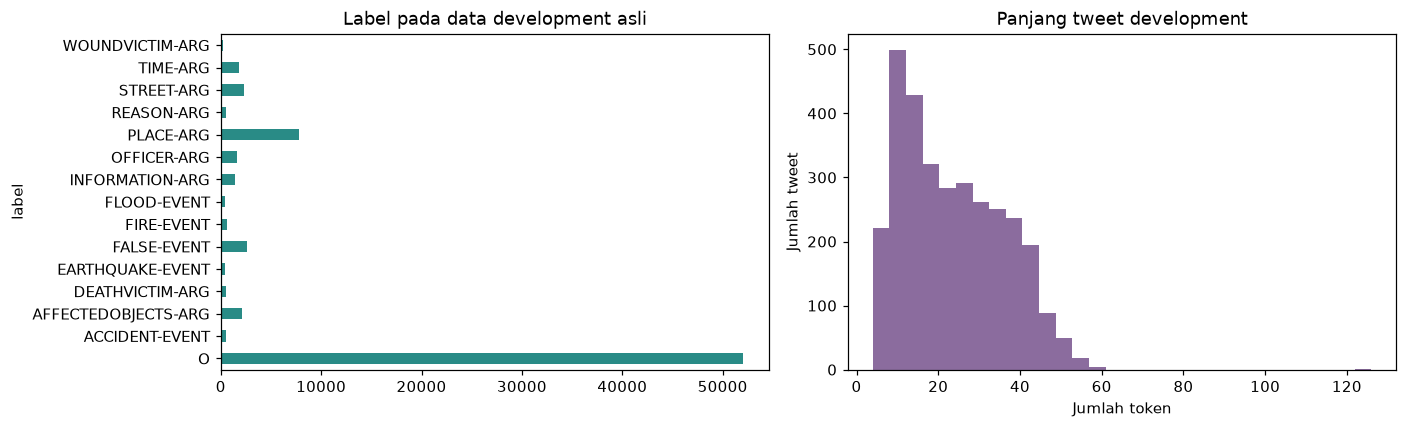

In [2]:
srl.eda(state)


## 4. Hasil reproduksi awal — Checkpoint 1

Bagian ini memuat angka historis dari ZIP Checkpoint 1. Urutan test direkonstruksi dari kode split asli dengan seed 42, lalu panjang prediksi, label, dan metrik diperiksa. Kecocokan ini bukan bukti bahwa ID test identik dengan paper.

Pada kode awal, pseudo-label ditambahkan sebelum split ulang sehingga validation berubah antar-iterasi. Model final dan analisis historis yang bergantung test tetap ditandai sebagai hasil protokol awal. Bobot keluarga yang disimpan sebagai `best` tidak otomatis merupakan bobot setiap threshold; tabel hasil tersimpan tidak membuktikan semua checkpoint tersedia.


In [3]:
srl.legacy_results(state)


Skor lama dipertahankan. Tidak digunakan untuk memilih model protokol perbaikan.


,model,threshold,test_f1_w,status,checkpoint_status
0,BiLSTM (Adam lr 1e-3),0.7,0.863169,metrik cocok; urutan direkonstruksi dari seed/...,result_only_no_matching_weights
1,BiLSTM (Adam lr 1e-3),0.8,0.865373,metrik cocok; urutan direkonstruksi dari seed/...,result_only_no_matching_weights
2,BiLSTM (Adam lr 1e-3),0.9,0.868395,metrik cocok; urutan direkonstruksi dari seed/...,available
3,BiLSTM (Adam lr 1e-3),NaN,0.851303,metrik cocok; urutan direkonstruksi dari seed/...,available
4,BiLSTM,0.7,0.605198,metrik cocok; urutan direkonstruksi dari seed/...,available
5,BiLSTM,0.8,0.563665,metrik cocok; urutan direkonstruksi dari seed/...,result_only_no_matching_weights
6,BiLSTM,0.9,0.563665,metrik cocok; urutan direkonstruksi dari seed/...,result_only_no_matching_weights
7,BiLSTM,NaN,0.563665,metrik cocok; urutan direkonstruksi dari seed/...,available
8,CRF,NaN,0.877869,metrik cocok; urutan direkonstruksi dari seed/...,available
9,IndoBERT,0.7,0.906965,metrik cocok; urutan direkonstruksi dari seed/...,result_only_no_matching_weights


## 5. Audit metodologi — dipindahkan dari notebook audit Checkpoint 2

Penjelasan audit sumber dipertahankan di bawah untuk merekam alasan perbaikan. Kalimat yang menyebut hasil “notebook ini” pada kutipan audit merujuk **notebook audit sumber**, bukan bukti eksekusi laporan gabungan. Angka aktual dan kelengkapan diambil dari sel komputasi laporan ini.


### 16.5 Audit metodologi: paper, notebook awal, dan notebook revisi

#### 16.5.1 Tujuan audit dan batas klaim

Bagian ini membedakan **metode yang secara eksplisit tertulis dalam paper**, **perilaku yang terlihat dalam kode notebook pertama**, dan **protokol yang digunakan pada notebook revisi**. Perbedaan metode perlu dicatat agar reproduksi dan pengembangan penelitian tidak dianggap identik.

**Sumber primer:** Ariyanto dkk. (2025), *Transformer-Based Semantic Role Labeling for Crisis Events Using Semi-Supervised Learning on Low-Resource Language Twitter Texts*, Algorithm 1 (langkah 14–20) dan Experimental Setup. DOI: https://doi.org/10.1109/ACCESS.2025.3604068. **Sumber kode historis:** `Checkpoint1_SRL_FALSE-EVENT(7).ipynb`, terutama fungsi `record()` dan bagian *final model* serta *error analysis*. **Sumber metodologi tambahan:** dokumentasi scikit-learn tentang data leakage dan model selection, serta kajian *Avoiding common machine learning pitfalls* (tautan ada pada Bagian 16.6).

| Aspek | Paper Ariyanto et al. (2025) | Notebook pertama (kode yang diperiksa) | Notebook revisi (keputusan penelitian) |
|---|---|---|---|
| Pseudo-label baru | `L ← L ∪ S`, kemudian data gabungan diproses dan di-split kembali (Algorithm 1, langkah 14–17) | Mengikuti pembagian ulang gabungan data | Pseudo-label hanya menambah data **training** |
| Validation setelah self-training | Algorithm 1 meminta pembagian ulang `D_train`/`D_val`; rincian perlindungan independensi tidak dijelaskan | Pembagian ulang; sebagian target validation dapat berasal dari model sendiri | **630 tweet berlabel asli**, dipisah satu kali dan tetap |
| Kapan self-training berhenti | Tidak ada pseudo-label baru yang lolos | Mengikuti alur tersebut | Sama; early stopping epoch tetap berdasarkan **validation loss** |
| Checkpoint akhir/terbaik | Pseudocode mengembalikan model setelah self-training selesai; **aturan seleksi iterasi lewat F1 validation tidak dinyatakan** | Rekaman model/konfigurasi terbaik dipengaruhi **F1 test** | Epoch terbaik menurut validation loss; iterasi, model, dan threshold menurut **F1 validation** |
| Error analysis | Menjelaskan confusion matrix dan kesalahan model terbaik pada hasil pengujian | `gold = [t["labels"] for t in test]` dan `pred = RES[key]["pred"]`: **data test** | **Validation** dari checkpoint final; test hanya untuk pelaporan akhir |
| Makna F1 di Tabel 7 | **Metrik test**, termasuk IndoBERT θ = 0,9, F1 = 0,863 | F1 test dibandingkan dengan F1 paper | **F1 test dibandingkan dengan F1 test paper**; F1 validation untuk model selection |

#### 16.5.2 Pseudo-label masuk kembali ke validation: apakah keliru?

**Temuan dari paper:** Algorithm 1 menggabungkan pseudo-label yang lolos ke himpunan `L`, lalu membagi ulang himpunan tersebut menjadi training dan validation. Dengan pembacaan literal, sebagian pseudo-label **dapat** masuk validation. Namun, paper tidak memberikan informasi cukup untuk memastikan bagaimana pemisahan dan identitas data pada implementasi sebenarnya dijaga. Oleh karena itu, penggunaan kata **berisiko** lebih tepat daripada mengklaim penulis telah terbukti melakukan data leakage.

**Mengapa berisiko secara evaluasi?** Validation idealnya mengukur ketepatan prediksi model terhadap **ground truth independen**. Jika label validation adalah hasil prediksi model itu sendiri, skor validasi dapat menunjukkan kesesuaian model dengan pseudo-label, bukan ketepatan terhadap anotasi manusia. Ketika data gabungan dibagi ulang, sampel yang pernah digunakan untuk melatih model dalam iterasi terdahulu juga berpotensi muncul sebagai validation pada iterasi berikutnya. Kedua kondisi ini melemahkan interpretasi validation loss dan validation F1.

**Apakah test otomatis bocor?** Tidak. Data test dapat tetap terpisah sepenuhnya. Risiko utamanya berada pada **independensi dan kualitas target validation**. Klaim kebocoran test memerlukan bukti tambahan, misalnya identitas tweet test masuk training atau metrik test digunakan untuk menyesuaikan metode.

**Keputusan penelitian:** Notebook revisi menetapkan 2.520 tweet berlabel untuk training dan **630 tweet berlabel asli untuk validation tetap**. Sebanyak 5.850 tweet tanpa label menjadi pool pseudo-label, yang lolos seleksi hanya ditambahkan ke training. Strategi tersebut merupakan **modifikasi metodologis** terhadap alur literal Algorithm 1, bukan reproduksi identik.

#### 16.5.3 Pemilihan model terbaik dari test: masalah evaluasi yang nyata pada notebook awal

Fungsi `record()` pada notebook pertama menghitung `m = evaluate([t["labels"] for t in test], pred)`. Nilai `m["f1_w"]` kemudian dipakai untuk memperbarui bobot *best* tiap keluarga model. Bagian pemilihan akhir memakai ekspresi yang sepadan dengan `max(cands, key=lambda k: RES[k]["metrics"]["f1_w"])`. Karena `metrics` dihitung dari test, **pemilihan konfigurasi terbaik pada notebook awal memang menggunakan test F1**.

Secara metodologis, hal itu disebut **test-set selection bias** atau *test contamination through model selection*. Test set digunakan untuk dua keputusan sekaligus, yaitu memilih model dan menilai generalisasi model terpilih. Hasil test berpotensi optimistis meskipun kode tidak pernah memanggil `fit()` pada data test. Pedoman scikit-learn menegaskan bahwa test set tidak digunakan untuk memilih model; analisis model selection juga membahas bias saat data evaluasi ikut menentukan kandidat pemenang.

**Batas interpretasi terhadap paper:** Tabel 7 paper melaporkan perbandingan **test F1** dan menyebut konfigurasi berperforma terbaik. Pernyataan tersebut **tidak cukup untuk membuktikan** bahwa penulis memakai test saat memilih checkpoint selama pengembangan. Menyebut konfigurasi dengan skor test tertinggi dalam laporan hasil juga dapat menjadi analisis deskriptif, bukan otomatis pelanggaran. Kritik pemilihan berdasarkan test dalam paragraf ini secara langsung mengacu pada **kode notebook pertama**, bukan tuduhan yang telah dibuktikan terhadap penulis paper.

**Keputusan penelitian:** Pemilihan model, threshold, dan iterasi menggunakan validation. Satu checkpoint terpilih dibekukan sebelum pengujian pada 1.000 tweet test. Pemeriksaan test lama secara berulang selama desain penelitian merupakan keterbatasan historis; hasil revisi tidak otomatis memulihkan independensi yang sudah terpengaruh pengambilan keputusan sebelumnya.

#### 16.5.4 Error analysis pada test: boleh untuk laporan, tetapi ada batasnya

**Error analysis pada test tidak otomatis keliru.** Paper menggunakan confusion matrix dan contoh kesalahan untuk mendeskripsikan kelemahan model yang telah dievaluasi. Ini wajar dalam tahap pelaporan akhir, selama analisis tidak digunakan untuk mengubah model atau mengklaim pengujian independen yang sama berulang kali.

**Masalah muncul bila hasil test memandu pengembangan**: misalnya, peneliti melihat kesalahan `FLOOD-EVENT → FALSE-EVENT` pada test, membuat modul khusus untuk mengatasi pola tersebut, lalu memilih model dan mengukur peningkatan akhir pada test yang sama. Rangkaian itu membuat data test memengaruhi desain model, sehingga skor setelah perbaikan tidak lagi murni merupakan evaluasi independen.

**Keputusan penelitian:** Error analysis utama untuk merumuskan N1–N4 menggunakan **validation berlabel asli** dari checkpoint final terpilih. Hasil test digunakan setelah pemilihan dibekukan, untuk pelaporan F1 dan perbandingan dengan paper. Analisis test yang bersifat deskriptif dapat menjadi lampiran akhir, sedangkan pemilihan ulang atau penyetelan metode memerlukan test baru yang independen.

#### 16.5.5 Alur evaluasi revisi dan konsekuensinya

1. Sebanyak 4.150 tweet berlabel dibagi menjadi **3.150 data pengembangan** dan **1.000 data test**. Selanjutnya, 3.150 data pengembangan dibagi menjadi 2.520 training dan 630 validation tetap.
2. Model awal dilatih dengan pemilihan epoch berdasarkan **validation loss minimum**. Pada setiap iterasi, pseudo-label diseleksi dari pool unlabeled dan hanya digunakan untuk training.
3. Iterasi berlanjut sampai tidak ada pseudo-label yang lolos threshold. Checkpoint epoch terbaik setiap iterasi ditentukan menurut validation loss.
4. Dari checkpoint yang tersimpan, pemilihan **iterasi, model, dan threshold berdasarkan weighted F1 validation tertinggi** dilakukan sebelum pengukuran test, disertai penyimpanan identitas dan jalur checkpoint.
5. Checkpoint terpilih digunakan untuk **error analysis pada 630 validation** dan **evaluasi akhir pada 1.000 test**.
6. Perbandingan menggunakan **test F1 vs test F1** paper, dengan catatan split sampel test asli paper tidak sepenuhnya tersedia dan protokol pemilihan checkpoint berbeda.

**Catatan metodologis tambahan:** Validation tetap tidak sepenuhnya kebal dari *overfitting* akibat penggunaan berulang. Karena itu, jumlah eksperimen perlu dicatat, keputusan novelty dibakukan sebelum melihat hasil final, dan kesimpulan sebaiknya diuji kembali pada data independen jika tersedia.

#### 16.5.6 Hubungan dengan research gap dan novelty

Perbaikan validation dan model selection merupakan **landasan validitas eksperimen** serta *reproducibility*, bukan klaim bahwa praktik tersebut baru ditemukan pada penelitian ini. Novelty yang diusulkan tetap **N1: joint tweet–token fact-aware SRL** dan **N2: semantic role-aware pseudo-label filtering**. N3 (backbone lebih baru) dan N4 (CRF) merupakan eksperimen pendukung.

Untuk mengukur dampak perubahan protokol tanpa mencampurnya dengan novelty, penelitian dapat menambahkan **studi sensitivitas atau ablation protokol**: (A) pembagian ulang train–validation menurut pembacaan Algorithm 1, (B) validation berlabel asli tetap, dengan checkpoint dan kriteria evaluasi lain disamakan sebisa mungkin. Perbandingan tersebut menguji dampak keseluruhan strategi pembagian data, bukan membuktikan bahwa satu-satunya penyebab perbedaan F1 adalah pseudo-label masuk validation.

**Kesimpulan audit:** Pembagian ulang setelah pseudo-label adalah **prosedur yang tertulis dalam Algorithm 1**, tetapi mempunyai risiko validasi. Pemilihan model berdasarkan **test F1 pada notebook pertama** adalah masalah evaluasi yang terkonfirmasi dari kode. **Error analysis menggunakan test** dapat diterima sebagai analisis akhir deskriptif, tetapi tidak sebagai dasar perbaikan yang terus diuji pada test yang sama. Keputusan revisi menjaga pemisahan ketiga fungsi tersebut.


**Catatan verifikasi paper:** aturan split ulang tercantum eksplisit pada Algorithm 1. Pernyataan seleksi terbaik melalui test harus dibaca sebagai interpretasi reproduksi, sebab paper tidak memberikan prosedur pemilihan lengkap.


## 6. Protokol perbaikan dan audit split

Validation tetap 630 tweet asli, fit-train 2.520, test 1.000. Pseudo-label masuk fit-train saja.
Setiap run diverifikasi melalui hash konfigurasi, dataset, dan daftar split tersimpan. Irisan ID harus nol; kemiripan/teks identik dilaporkan terpisah tanpa mengganti split hasil training yang sudah ada.

Perbaikan juga mencakup packed sequence pada BiLSTM. Karena implementasi lama memproses padding dengan cara berbeda, selisih hasil bukan estimasi kausal efek split saja. Kosakata dibangun dari fit-train dan korpus unlabeled sesuai run; validasi tidak dipakai untuk membangun kosakata supervised.


In [4]:
srl.audit_splits(state)


ID train/validation/test terpisah. Pseudo-label tersimpan terpisah dari validation/test.
Irisan teks dilaporkan apa adanya; tidak mengubah split eksperimen yang sudah dilatih.


,run_id,a,b,irisan_id,irisan_teks_normalisasi
0,c1916485a4ed,fit_train,validation,0,0
1,c1916485a4ed,fit_train,test,0,0
2,c1916485a4ed,validation,test,0,0


## 7. Hasil perbaikan dan pemilihan model berdasarkan validation

Hanya checkpoint stage yang memiliki `best.pt` **dan** metadata `complete.json` yang dievaluasi.
Epoch terbaik diperiksa terhadap minimum validation loss pada riwayat stage. Iterasi dan konfigurasi dipilih dari validation weighted F1 terbesar; seri dipecahkan secara deterministik.

Run belum selesai tidak dilanjutkan. Pemilihan dibatasi pada stage selesai yang tersedia, dengan status parsial ditampilkan. Bobot `last.pt` atau `.tmp` tidak dijadikan checkpoint final secara diam-diam. Hasil lama yang sudah pernah menggunakan test tetap merupakan riwayat eksperimen; membekukan pilihan sekarang tidak menghapus akses test pada masa lalu.


In [5]:
srl.select_validation(state)


[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM/initial/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_1/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_2/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_3/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_4/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_5/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_6/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_7/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_8/best.pt
[INFERENSI validation] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages

,run_id,family,threshold,iteration,epoch,val_f1_w,training_status
0,c1916485a4ed,BiLSTM,NaN,0,10.0,0.562374,initial_complete
1,c1916485a4ed,BiLSTM,0.9,0,10.0,0.562374,complete
2,c1916485a4ed,BiLSTM,0.8,0,10.0,0.562374,complete
3,c1916485a4ed,BiLSTM,0.7,30,2.0,0.743250,complete
4,c1916485a4ed,IndoBERT,NaN,0,4.0,0.902738,initial_complete
5,c1916485a4ed,IndoBERT,0.9,11,1.0,0.909830,complete
6,c1916485a4ed,IndoBERT,0.8,4,2.0,0.910858,complete
7,c1916485a4ed,IndoBERT,0.7,3,1.0,0.907124,complete
8,c1916485a4ed,CRF,NaN,0,NaN,0.871489,complete


## 8. Test setelah pilihan validation dibekukan

File pemilihan final disimpan sebelum tahap test dalam eksekusi ini. Test seluruh konfigurasi tersedia dipakai untuk pelaporan, bukan mengubah keputusan final. Prediksi ditautkan ke hash checkpoint dan urutan ID; cache hanya digunakan bila sumber dan konfigurasi cocok.


In [6]:
srl.report_test(state)


[INFERENSI test] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM/initial/best.pt
[INFERENSI test] c1916485a4ed BiLSTM: outputs/runs/c1916485a4ed/stages/BiLSTM_0_7/iter_30/best.pt
[INFERENSI test] c1916485a4ed IndoBERT: outputs/runs/c1916485a4ed/stages/IndoBERT/initial/best.pt
[INFERENSI test] c1916485a4ed IndoBERT: outputs/runs/c1916485a4ed/stages/IndoBERT_0_9/iter_11/best.pt
[INFERENSI test] c1916485a4ed IndoBERT: outputs/runs/c1916485a4ed/stages/IndoBERT_0_8/iter_4/best.pt
[INFERENSI test] c1916485a4ed IndoBERT: outputs/runs/c1916485a4ed/stages/IndoBERT_0_7/iter_3/best.pt
[INFERENSI test] c1916485a4ed CRF: outputs/runs/c1916485a4ed/models/CRF/model.pkl


,run_id,family,threshold,val_f1_w,test_f1_w,test_macro_noO,training_status
0,c1916485a4ed,BiLSTM,NaN,0.562374,0.565399,0.001302,initial_complete
1,c1916485a4ed,BiLSTM,0.9,0.562374,0.565399,0.001302,complete
2,c1916485a4ed,BiLSTM,0.8,0.562374,0.565399,0.001302,complete
3,c1916485a4ed,BiLSTM,0.7,0.743250,0.742189,0.364100,complete
4,c1916485a4ed,IndoBERT,NaN,0.902738,0.902548,0.736876,initial_complete
5,c1916485a4ed,IndoBERT,0.9,0.909830,0.905802,0.752665,complete
6,c1916485a4ed,IndoBERT,0.8,0.910858,0.907274,0.753270,complete
7,c1916485a4ed,IndoBERT,0.7,0.907124,0.902821,0.740849,complete
8,c1916485a4ed,CRF,NaN,0.871489,0.873922,0.668603,complete


## 8. Perbandingan hasil awal, percobaan validasi tetap, dan paper

Perbandingan menggunakan hasil test pada model/threshold yang sama. Perbedaan split dan implementasi membatasi klaim kesetaraan. Grafik tidak menentukan model final. Diagnosis train/validation loss dibaca per stage karena komposisi pseudo-label berubah antar-iterasi.


### Perbandingan metode yang sama

Satu baris = **model dan threshold yang sama**. Semua angka utama adalah **F1 test**, bukan F1 validation. Validation hanya digunakan untuk memilih checkpoint perbaikan. Model tanpa pasangan hasil pada ketiga sumber tidak masuk tabel ini.

Model,Threshold,F1 test — Paper,F1 test — Checkpoint 1,F1 test — Validasi tetap,Δ perbaikan − CP1,Δ perbaikan − paper,Status perbaikan
BiLSTM,0.7,0.5600,0.6052,0.7422,0.1370,0.1822,selesai
BiLSTM,0.8,0.5900,0.5637,0.5654,0.0017,-0.0246,selesai
BiLSTM,0.9,0.5900,0.5637,0.5654,0.0017,-0.0246,selesai
IndoBERT,0.7,0.7210,0.9070,0.9028,-0.0041,0.1818,selesai
IndoBERT,0.8,0.8180,0.9070,0.9073,0.0003,0.0893,selesai
IndoBERT,0.9,0.8630,0.9066,0.9058,-0.0008,0.0428,selesai


**Batas perbandingan:** model/threshold dipasangkan, tetapi protokol split dan beberapa detail implementasi berbeda. Selisih bukan bukti kausal efek perbaikan split saja. Baris parsial belum menyelesaikan seluruh self-training. Definisi averaging F1 paper juga belum dapat dipastikan identik.

### Pemeriksaan overfitting dan underfitting

**Validation loss saja tidak cukup.** Overfitting dapat dicurigai ketika train loss terus turun sementara validation loss naik. Aturan deskriptif di sini mencari pola tersebut pada dua transisi epoch berurutan setelah minimum validation loss, dengan perubahan lebih dari 0,0001. Ini indikator, bukan diagnosis pasti.

Checkpoint,Epoch minimum val loss,Train loss pada epoch tersebut,Validation loss minimum,Validation loss terakhir,Epoch tersimpan,Indikasi
BiLSTM | iterasi 0 | BiLSTM,10,1.7956,1.7096,1.7096,10,validation masih membaik; belum cukup bukti konvergensi/underfitting
BiLSTM | iterasi 30 | BiLSTM_0_7,2,0.1776,0.8406,0.8829,5,indikasi overfitting setelah epoch minimum validation loss
IndoBERT | iterasi 0 | IndoBERT,4,0.1974,0.2942,0.3212,7,indikasi overfitting setelah epoch minimum validation loss
IndoBERT | iterasi 11 | IndoBERT_0_9,1,0.0259,0.5379,0.6260,4,indikasi overfitting setelah epoch minimum validation loss
IndoBERT | iterasi 4 | IndoBERT_0_8,2,0.0595,0.3977,0.4964,5,indikasi overfitting setelah epoch minimum validation loss
IndoBERT | iterasi 3 | IndoBERT_0_7,1,0.0897,0.3737,0.4422,4,indikasi overfitting setelah epoch minimum validation loss


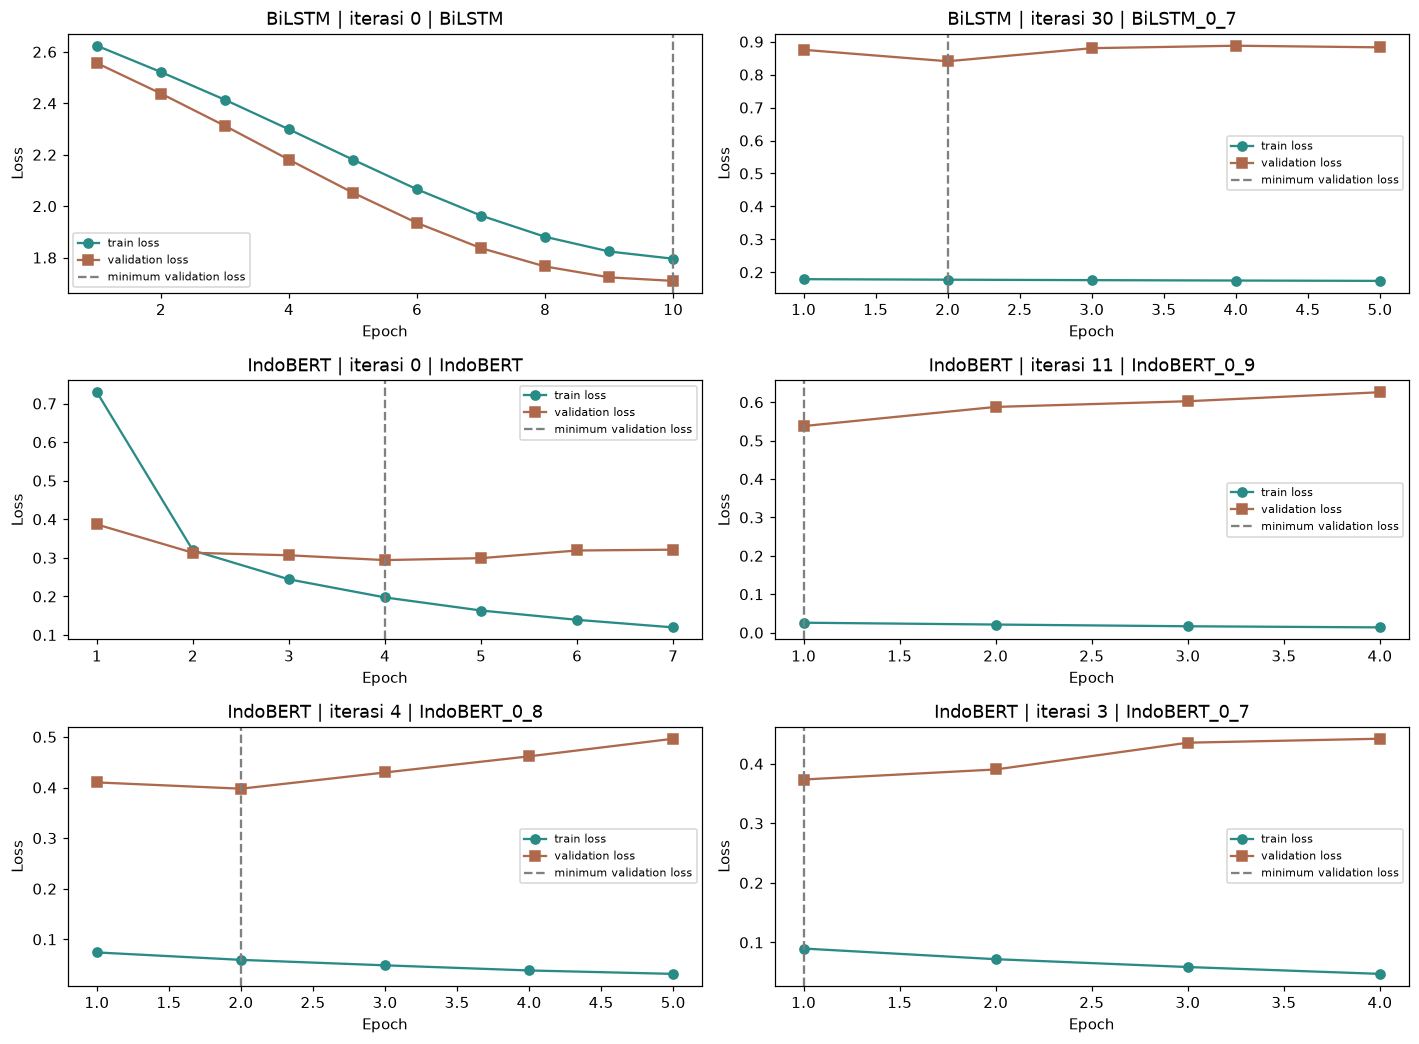

**Underfitting belum dapat dipastikan dari log ini:** perlu memeriksa apakah performa train dan validation sama-sama rendah terhadap baseline serta apakah keduanya masih membaik. Tidak ada ambang loss universal. Train loss dicatat selama training (dropout aktif dan bobot berubah), sedangkan validation loss dihitung pada akhir epoch; besar gap tidak boleh dibaca sebagai ukuran yang sepenuhnya setara. Kurva dipisahkan per stage karena komposisi pseudo-label berubah antar-iterasi. CRF tidak memiliki kurva epoch neural. Untuk run ini, checkpoint minimum validation loss sudah dipakai sehingga epoch sesudahnya tidak otomatis menjadi model final.

In [7]:
srl.compare(state)


### Analisis percobaan: indikasi overfitting dan batas kesimpulan

Riwayat IndoBERT tanpa self-training memperlihatkan train loss turun dari **0,1974 (epoch 4)** menjadi **0,1198 (epoch 7)**, sementara validation loss naik dari **0,2942** menjadi **0,3212**. Pola ini menunjukkan indikasi overfitting setelah epoch minimum validation loss. Checkpoint yang dipakai adalah epoch 4, bukan epoch terakhir.

Pada IndoBERT threshold **0,8**, iterasi terpilih **4**, validation loss minimum **0,3977 (epoch 2)** meningkat menjadi **0,4964 (epoch 5)**. Diagnosis riwayat loss juga mencatat indikasi overfitting pada beberapa stage self-training. Temuan ini tidak berlaku otomatis untuk semua model; BiLSTM awal masih menunjukkan validation loss membaik pada akhir log.

Checkpoint IndoBERT threshold 0,8 mempunyai weighted F1 validation **0,9109** dan test **0,9073** (selisih sekitar **0,0036**). Gap F1 ini kecil; kurva loss sesudah epoch terbaik tidak cukup untuk menyatakan checkpoint terpilih gagal generalisasi. Weighted F1 perlu dibaca bersama macro-F1 tanpa O dan span-F1 karena dominasi label O.

**Penempatan dalam laporan:** masukkan sebagai *analisis percobaan perbaikan protokol validasi*. Validation asli tetap dan pseudo-label hanya pada training memperbaiki prosedur evaluasi, tetapi tidak menjamin bebas overfitting. Hasil tetap dilaporkan bersama kurva loss, aturan pemilihan checkpoint, dan keterbatasan; jangan menyimpulkan penurunan/kenaikan skor disebabkan perubahan split saja. Tidak ada training baru dalam analisis ini.


## 10. Error analysis pada validation — checkpoint final yang sama

Confusion matrix, F1 per label, confidence, dan contoh token salah di bawah berasal dari validation asli model final. File checkpoint dan hash yang dipakai sama dengan tahap test, sehingga analisis tidak memuat model lain secara tidak sengaja.


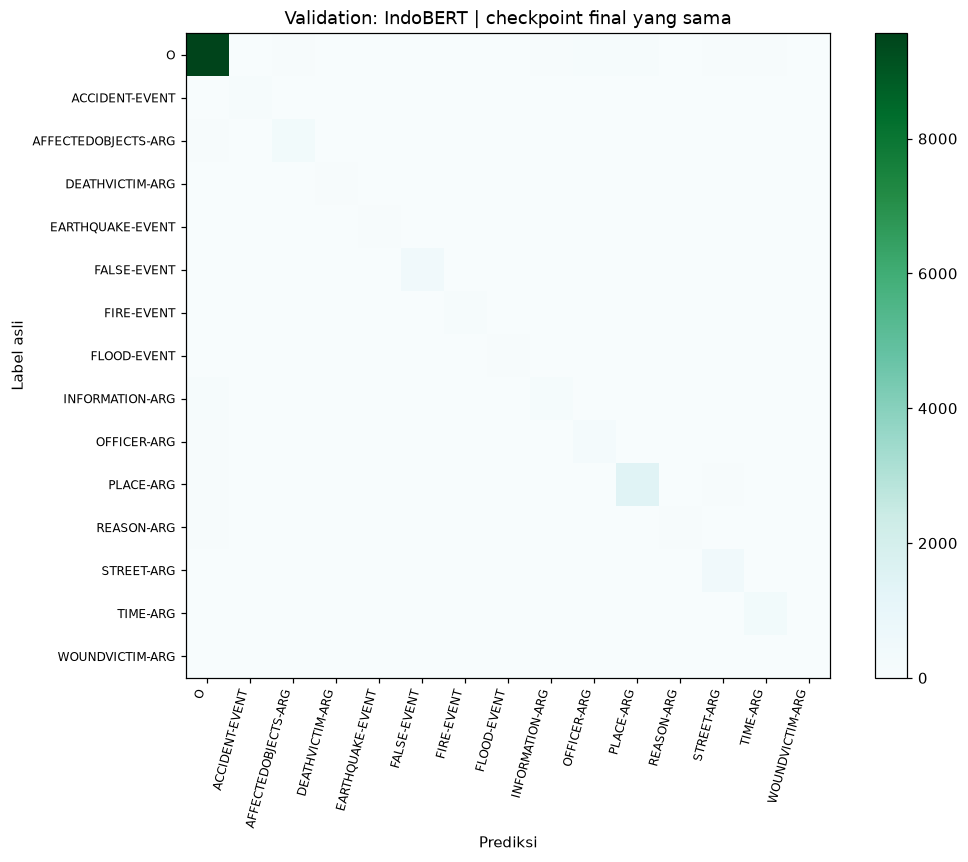

,precision,recall,f1,support
O,0.9607,0.9394,0.9499,10180.0
ACCIDENT-EVENT,0.8393,0.9038,0.8704,104.0
AFFECTEDOBJECTS-ARG,0.7877,0.8013,0.7944,463.0
DEATHVICTIM-ARG,0.4896,0.8246,0.6144,57.0
EARTHQUAKE-EVENT,0.7368,0.7179,0.7273,78.0
FALSE-EVENT,0.8457,0.8818,0.8634,516.0
FIRE-EVENT,0.9429,0.8609,0.9000,115.0
FLOOD-EVENT,0.7639,0.6471,0.7006,85.0
INFORMATION-ARG,0.6534,0.5449,0.5942,301.0
OFFICER-ARG,0.7125,0.8657,0.7817,335.0


,text_id,token_index,token,gold,pred,confidence,context
0,BAN-01176,3,majelis,OFFICER-ARG,O,0.999799,belasungkawa dan doa majelis rasulullaah terha...
1,BAN-01176,4,rasulullaah,OFFICER-ARG,O,0.999349,belasungkawa dan doa majelis rasulullaah terha...
2,BAN-01570,11,9691,WOUNDVICTIM-ARG,O,0.892849,pengungsi banjir bandang di sentani terus bert...
3,BAN-01570,12,orang,WOUNDVICTIM-ARG,O,0.877362,pengungsi banjir bandang di sentani terus bert...
4,BAN-01570,25,alam,O,PLACE-ARG,0.590568,pengungsi banjir bandang di sentani terus bert...
5,BAN-01570,26,cycloops,O,PLACE-ARG,0.795423,pengungsi banjir bandang di sentani terus bert...
6,KEB-00961,5,mall,AFFECTEDOBJECTS-ARG,PLACE-ARG,0.837942,""" telah terjadi kebakaran di mall taman anggre..."
7,KEB-00961,6,taman,AFFECTEDOBJECTS-ARG,PLACE-ARG,0.983185,""" telah terjadi kebakaran di mall taman anggre..."
8,KEB-00961,7,anggrek,AFFECTEDOBJECTS-ARG,PLACE-ARG,0.964180,""" telah terjadi kebakaran di mall taman anggre..."
9,BAN-00040,1,banjir,FALSE-EVENT,FLOOD-EVENT,0.637322,| banjir : 3 sekolah di kluang ditutup


In [8]:
srl.error_analysis(state)


## 12. Inferensi model final

Contoh inferensi memakai checkpoint terpilih berdasarkan validation. Dua kalimat demonstrasi berikut bukan evaluasi statistik dan bukan pengganti test.


In [10]:
srl.inference_demo(state)


banjir setinggi 1 meter merendam rumah di solo sejak minggu malam
{"FLOOD-EVENT": ["banjir"], "INFORMATION-ARG": ["setinggi 1 meter"], "AFFECTEDOBJECTS-ARG": ["rumah"], "PLACE-ARG": ["solo"], "TIME-ARG": ["minggu"]}
warga diimbau waspada potensi banjir rob di pesisir semarang
{"FLOOD-EVENT": ["banjir rob"], "PLACE-ARG": ["semarang"]}


## 13. Keterbatasan, kelengkapan, dan kesimpulan

- Hasil protokol awal tidak menjadi hasil bebas kebocoran setelah dievaluasi ulang.
- Audit ID membuktikan pemisahan ID; teks identik/kemiripan semantik dapat tetap membatasi independensi sampel.
- Tidak ada training baru. Stage yang terputus dan eksperimen tanpa bobot ditandai belum tersedia, bukan diisi angka perkiraan.
- Beberapa file JSON lama memiliki teks nama yang mengalami encoding rusak; identitas laporan menggunakan family, threshold, run, dan lokasi checkpoint yang terverifikasi.
- Paper tidak merilis ID split lengkap dalam bahan proyek. Angka weighted F1 dan span F1 perlu dibaca bersama, dengan perbedaan implementasi dijelaskan.
- Konfigurasi dan seluruh bobot sumber tetap tersimpan. Manifest memetakan file ke protokol, hash, status kelengkapan, dan duplikasi isi.

Kesimpulan numerik berikut dihasilkan dari hasil aktual eksekusi ini, bukan salinan output notebook lama.


In [11]:
summary = srl.finish(state)


**Selesai tanpa training.** 14 hasil Checkpoint 1, 9 konfigurasi perbaikan yang dapat dievaluasi, dan 0 hasil Komodo eksternal. Cache dipakai 9 kali; inferensi dataset baru 63 kali.

Model final pada **checkpoint selesai yang tersedia**: **IndoBERT**, threshold 0.8, iterasi 4, run `c1916485a4ed`; validation weighted F1 **0.9109**. Training yang belum selesai tetap ditandai parsial; tidak ada klaim semua eksperimen selesai.

## 14. Referensi dan peta artefak

1. Ariyanto dkk. (2025), *Transformer-Based Semantic Role Labeling for Crisis Events Using Semi-Supervised Learning on Low-Resource Language Twitter Texts*, IEEE Access, DOI 10.1109/ACCESS.2025.3604068. [PDF lokal](archive/paper.pdf).
2. Dataset *Semantic Role Labeling Datasets for Crisis Event*, Mendeley Data v2, DOI 10.17632/r76v5sjyv2.2.
3. Notebook reproduksi dan audit asli: `archive/checkpoint1/`; notebook perbaikan sebelum penggabungan: `archive/before_unification/`.
4. Hasil awal: `outputs/legacy_checkpoint1/`; run perbaikan: `outputs/runs/`.
5. Laporan aktif: `outputs/unified/`; manifest sumber ZIP: `archive/source_inventory.json`; manifest seluruh artefak: `outputs/unified/artifact_manifest.json`.
